# Chapter 13: Generating Lots of Text with Decoder-Only Transformers!!!

In [1]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [2]:
names = {'john': 'yes !', 'jack': 'no !'}
frames = [
    'is {} cool ?',
    'hey is {} cool ?',
    'tell me is {} cool ?',
    'do you think {} is cool ?',
    'so is {} cool or not ?',
    '{} is cool right ?',
    'would you say {} is cool ?',
    'honestly is {} cool ?',
]
held_out = {('john', 2), ('john', 5), ('jack', 3), ('jack', 6)}
exclamation_mark_token = '!'
pad_token = '<PAD>'

train_data = []
test_data = []

for name, answer in names.items():
    for frame_index, frame in enumerate(frames):
        sequence = f'{frame.format(name)} {answer}'

        if (name, frame_index) in held_out:
            test_data.append(sequence)
        else:
            train_data.append(sequence)
            
words = sorted({word for sequence in train_data + test_data for word in sequence.split()})

words.insert(0, pad_token)

exclamation_mark_token_id = words.index(exclamation_mark_token)
pad_token_id = words.index(pad_token)
words_counts = len(words)
word_to_index_dictionary = {}

for word_index, word in enumerate(words):
    word_to_index_dictionary[word] = word_index

In [3]:
test_data

['tell me is john cool ? yes !',
 'john is cool right ? yes !',
 'do you think jack is cool ? no !',
 'would you say jack is cool ? no !']

In [4]:
def get_data_loader(data, is_test_data=False):
    X_raw = []
    y_raw = []
    
    for sentence in data:
        words_in_sentence = sentence.split()
        token_ids_in_sentence = [word_to_index_dictionary[word_in_sentence] for word_in_sentence in words_in_sentence]
        
        if is_test_data:
            X_part = token_ids_in_sentence[:(len(words_in_sentence) - 2)]
            y_part = token_ids_in_sentence[(len(words_in_sentence) - 2):]
        else:
            X_part = token_ids_in_sentence[:-1]
            y_part = token_ids_in_sentence[1:]      
        
        X_raw.append(torch.tensor(X_part).int())
        y_raw.append(torch.tensor(y_part).int())

    X_tensor = pad_sequence(X_raw, batch_first=True)
    y_tensor = pad_sequence(y_raw, batch_first=True)

    tensor_data = TensorDataset(X_tensor, y_tensor)
    data_loader = DataLoader(tensor_data, shuffle=True)
    
    return data_loader

train_data_loader = get_data_loader(train_data)
test_data_loader = get_data_loader(test_data, True)

In [5]:
embedding_dim = 8
qkv_dim = 8

class EncDecNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.dec_embedding = nn.Embedding(num_embeddings=words_counts, embedding_dim=embedding_dim)
        self.dec_queries = nn.Linear(qkv_dim, qkv_dim)
        self.dec_keys = nn.Linear(qkv_dim, qkv_dim)
        self.dec_values = nn.Linear(qkv_dim, qkv_dim)
        self.dec_linear = nn.Linear(embedding_dim, words_counts)
    
    @staticmethod
    def get_positional_encoding(x_param):
        token_positions = torch.arange(len(x_param)).unsqueeze(dim = 1)
        dimension_indices = torch.arange(0, embedding_dim, 2)
        frequencies = 1 / (10000 ** (dimension_indices / embedding_dim))
    
        positional_encoding = torch.zeros(len(x_param), embedding_dim)
        positional_encoding[:, 0::2] = torch.sin(token_positions * frequencies)
        positional_encoding[:, 1::2] = torch.cos(token_positions * frequencies)
    
        return positional_encoding

    def get_encoded_values(self, x_param):
        word_embedding = self.dec_embedding(x_param[0])
        positional_encoding = self.get_positional_encoding(x_param[0])
        encoded_values = word_embedding + positional_encoding

        return encoded_values
        
    @staticmethod
    def get_attention(query_param, key_param, value_param, mask_param):
        softmax_input = (torch.matmul(query_param, key_param.T)) / torch.sqrt(torch.tensor(qkv_dim))
        softmax_input = softmax_input + mask_param
        
        return torch.matmul(torch.softmax(softmax_input, dim=1), value_param)
    
    def get_dec_output(self, x_param):
        words_nr = len(x_param[0])
        
        dec_encoded_values = self.get_encoded_values(x_param)
        dec_queries = self.dec_queries(dec_encoded_values)
        dec_keys = self.dec_keys(dec_encoded_values)
        dec_values = self.dec_values(dec_encoded_values)
        dec_mask = torch.triu(torch.full((words_nr, words_nr), -torch.inf), diagonal=1)
        dec_attention = self.get_attention(dec_queries, dec_keys, dec_values, dec_mask)
        dec_output = dec_attention + dec_encoded_values
    
        return dec_output
        
    def forward(self, x_param, teacher_forcing=True):
        if teacher_forcing:
            dec_output = self.get_dec_output(x_param)

            return self.dec_linear(dec_output)
        else:
            max_steps = 3
            current_step = 0
            predicted_words = x_param

            while True:
                dec_output = self.get_dec_output(predicted_words)
                argmax_input = self.dec_linear(dec_output)

                new_predicted_word = torch.argmax(argmax_input, dim=1)[-1]
                predicted_words = torch.cat((predicted_words, torch.tensor([[new_predicted_word]])), dim=1)

                current_step += 1

                if current_step == max_steps or new_predicted_word == exclamation_mark_token_id:
                    break
                    
            return predicted_words.int()

In [6]:
enc_dec_net = EncDecNet()
optimizer = torch.optim.Adam(enc_dec_net.parameters())
loss_func = torch.nn.CrossEntropyLoss(ignore_index=pad_token_id)
losses = []

enc_dec_net.train()

for epoch in range(3000):
    for X, y in train_data_loader:
        y_pred = enc_dec_net(X)

        y_pred_target = y_pred
        y_target = y.squeeze().long()
        
        loss = loss_func(y_pred_target, y_target)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.detach().item())

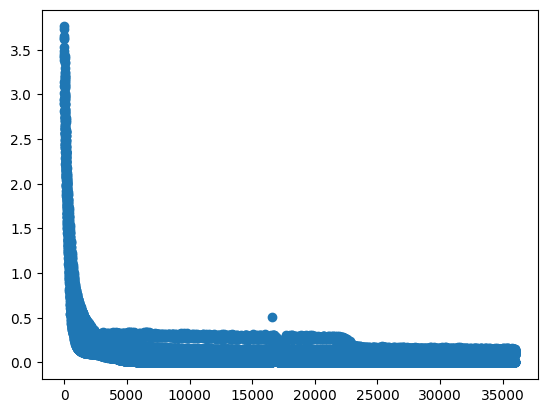

In [7]:
plt.scatter(range(len(losses)), losses)
plt.show()

In [8]:
def format_prediction(y_pred_param):
    return ' '.join([words[token_id] for token_id in y_pred_param[0]])

In [9]:
enc_dec_net.eval()

for X, y in test_data_loader:
    X = X[:, X[0] != pad_token_id]

    y_pred = enc_dec_net(X, teacher_forcing=False)

    y_pred_target = y_pred
    y_target = torch.cat((X, y), dim=1)

    print(y_pred_target)
    print(y_target)
    print(format_prediction(y_pred))
    print('---------------')

tensor([[19, 21, 15,  8,  7,  3,  2, 20,  1]], dtype=torch.int32)
tensor([[19, 21, 15,  8,  7,  3,  2, 11,  1]], dtype=torch.int32)
would you say jack is cool ? yes !
---------------
tensor([[ 4, 21, 18,  8,  7,  3,  2, 11,  1]], dtype=torch.int32)
tensor([[ 4, 21, 18,  8,  7,  3,  2, 11,  1]], dtype=torch.int32)
do you think jack is cool ? no !
---------------
tensor([[17, 10,  7,  9,  3,  2, 20,  1]], dtype=torch.int32)
tensor([[17, 10,  7,  9,  3,  2, 20,  1]], dtype=torch.int32)
tell me is john cool ? yes !
---------------
tensor([[ 9,  7,  3, 14,  2, 20,  1]], dtype=torch.int32)
tensor([[ 9,  7,  3, 14,  2, 20,  1]], dtype=torch.int32)
john is cool right ? yes !
---------------
